# Introduction to Machine Learning
## Assignment Section III: 
## Python Data Exercise (46 marks)
**BS Analytics, Semester V · School of Analytics, TISS Mumbai**

**How to use this notebook**
1. Run **every** cell in order, from the top (use *Runtime → Run all* if unsure). Cells marked **PROVIDED** must **NOT** be edited.
2. Cells marked **YOUR CODE HERE** are yours to complete. Written answers go in the markdown cells that follow each task, within the stated word limits (equations and tables do not count toward word limits; explanatory prose does).
3. Before submitting, use *Runtime → Restart session and run all* and confirm that the notebook runs from top to bottom without errors.
4. Enter your **official roll number** exactly once, in Task 0, in the form e.g. `M2024BSASS032` (capital M, no spaces). Do not change the individualization code, the seeds, or the assigned values.
5. Disclose any AI assistance in the declaration cell at the end.


### PROVIDED: Imports (DO NOT CHANGE or EDIT THIS)

In [1]:
import hashlib, json, re, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
                             accuracy_score, precision_score, recall_score, f1_score)


### PROVIDED: Simulated microloan dataset (DO NOT CHANGE or EDIT THIS)
Each row is one microloan made by a (fictional) rural lender. The target `default` is **1** if the borrower missed repayment within 12 months (positive class) and **0** if the loan was repaid (negative class).

| Column | Meaning |
|---|---|
| `age` | Borrower age in years |
| `monthly_income` | Household monthly income (₹); some values are missing |
| `loan_amount` | Loan amount (₹) |
| `term_months` | Loan term (6, 12, 18 or 24 months) |
| `prior_loans` | Number of earlier loans taken from this lender |
| `agri_income_share` | Share of household income from agriculture (0 to 1) |
| `branch_distance_km` | Distance to nearest bank branch (km); some values are missing |
| `savings_group` | 1 if the borrower belongs to a savings group, else 0 |
| `default` | **Target**: 1 = missed repayment (positive), 0 = repaid (negative) |

Kindly note that the data are **simulated**; they are not real borrowers and results do not carry over to real lending.


In [2]:
# Synthetic microloan portfolio dataset generator
# (imports repeated so this cell also works if the import cell above was skipped)
import hashlib, json, re, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
                             accuracy_score, precision_score, recall_score, f1_score)

MASTER_SEED = 20260101
MASTER_N = 3000
TARGET_RATE = 0.20


def make_master_dataset(n=MASTER_N, seed=MASTER_SEED, target_rate=TARGET_RATE):
    """Simulated microloan portfolio. Same output for everyone (fixed seed)."""
    rng = np.random.default_rng(seed)
    age = np.clip(rng.normal(38, 10, n), 21, 65).round()
    income = np.clip(rng.lognormal(np.log(15000), 0.45, n), 4000, 90000).round(-2)
    loan_amount = np.clip(income * rng.uniform(1.0, 4.0, n), 5000, 150000).round(-3)
    term_months = rng.choice([6, 12, 18, 24], size=n, p=[0.2, 0.4, 0.2, 0.2])
    prior_loans = np.clip(rng.poisson(1.5, n), 0, 8)
    agri_share = rng.beta(2, 2.5, n).round(2)
    distance_km = np.clip(rng.gamma(2.0, 4.0, n), 0.5, 40).round(1)
    savings_group = rng.binomial(1, 0.5, n)

    loan_to_income = loan_amount / income
    risk = (1.8 * (loan_to_income - 2.5)
            + 3.0 * (agri_share - 0.4)
            + 0.12 * (distance_km - 8)
            - 2.0 * savings_group
            - 0.60 * (prior_loans - 1.5)
            + 0.50 * (term_months - 12) / 6
            - 0.03 * (age - 38))

    # choose the intercept so that the average default probability equals target_rate
    lo, hi = -10.0, 10.0
    for _ in range(60):
        mid = (lo + hi) / 2
        if (1 / (1 + np.exp(-(mid + risk)))).mean() > target_rate:
            hi = mid
        else:
            lo = mid
    p_default = 1 / (1 + np.exp(-(lo + risk)))
    default = (rng.random(n) < p_default).astype(int)

    df = pd.DataFrame({
        "age": age,
        "monthly_income": income,
        "loan_amount": loan_amount,
        "term_months": term_months,
        "prior_loans": prior_loans,
        "agri_income_share": agri_share,
        "branch_distance_km": distance_km,
        "savings_group": savings_group,
        "default": default,
    })
    # a few values are missing (realistic data entry gaps)
    df.loc[rng.random(n) < 0.03, "monthly_income"] = np.nan
    df.loc[rng.random(n) < 0.02, "branch_distance_km"] = np.nan
    return df


def master_checksum(df):
    return hashlib.sha256(df.round(4).to_csv(index=True).encode("utf-8")).hexdigest()[:16].upper()


EXPECTED_MASTER_CHECKSUM = "2AFAEA208FCBF28D"   # reference value (you should not change this value)


### PROVIDED: Individualization functions (DO NOT CHANGE or EDIT THIS)
Your roll number is turned into a number (a *seed*) using SHA-256, which gives the same answer on every system and every run. 

The seed then decides 

**1.** which 900 loans from the master dataset you receive (always exactly 180 defaults and 720 repaid), 

**2.** your train/test split (80%/20%, stratified), and 

**3.** your assigned **K** for KNN and assigned **maximum depth** for the decision tree.


In [3]:
# (imports repeated so this cell also works if the import cell above was skipped)
import hashlib, json, re, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
                             accuracy_score, precision_score, recall_score, f1_score)

COURSE_SALT = "TISS-BSA-IML-2026"
K_OPTIONS = [3, 5, 7, 9, 11]
DEPTH_OPTIONS = [4, 5, 6, 7]
N_SAMPLE, N_POS = 900, 180
TEST_SIZE = 0.20


def normalise_roll(raw):
    roll = re.sub(r"[^0-9A-Za-z]", "", str(raw)).upper()   # drop spaces/separators, use capitals
    if len(roll) < 3:
        raise ValueError("Roll number looks too short. Please enter your official roll number.")
    if not re.fullmatch(r"M\d{4}[A-Z]+\d{3}", roll):
        print("NOTE: expected a roll number like M2024BSASS032; you entered", roll,
              "- please check it before continuing.")
    return roll


def make_assignment(roll, master):
    """Deterministic mapping: roll number -> seed, K, depth, sample, split."""
    digest = hashlib.sha256((COURSE_SALT + "|" + roll).encode("utf-8")).digest()
    seed = int.from_bytes(digest[:4], "big")
    k = K_OPTIONS[digest[4] % len(K_OPTIONS)]
    depth = DEPTH_OPTIONS[digest[5] % len(DEPTH_OPTIONS)]

    rng = np.random.default_rng(seed)
    pos_ids = master.index[master["default"] == 1].to_numpy()
    neg_ids = master.index[master["default"] == 0].to_numpy()
    chosen = np.concatenate([rng.choice(pos_ids, N_POS, replace=False),
                             rng.choice(neg_ids, N_SAMPLE - N_POS, replace=False)])
    rng.shuffle(chosen)
    data = master.loc[chosen]            # the index keeps the master row id

    X = data.drop(columns="default")
    y = data["default"]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, stratify=y, random_state=seed)

    # inner validation split (taken from the TRAINING part only) for choosing K, depth etc.
    X_fit, X_val, y_fit, y_val = train_test_split(
        X_train, y_train, test_size=0.20, stratify=y_train, random_state=(seed + 1) % (2 ** 32))

    version_id = hashlib.sha256(
        (roll + "|" + ",".join(map(str, sorted(chosen)))).encode("utf-8")).hexdigest()[:10].upper()
    return dict(seed=seed, k=k, depth=depth, version_id=version_id, student_data=data,
                X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test,
                X_fit=X_fit, X_val=X_val, y_fit=y_fit, y_val=y_val)


## Task 0: Setup and individualization (4 marks)

In [4]:
# PROVIDED: run once. Enter your official roll number when asked. (2 marks) 
roll_raw = input("Enter your official roll number: ")
ROLL = normalise_roll(roll_raw)

master = make_master_dataset()
MASTER_CHECK = master_checksum(master)
if MASTER_CHECK != EXPECTED_MASTER_CHECKSUM:
    warnings.warn("Master dataset checksum differs from the reference value. "
                  "Your library versions may differ; tell your instructor and include this warning in your submission.")

assignment = make_assignment(ROLL, master)
SEED, K_ASSIGNED, DEPTH_ASSIGNED = assignment["seed"], assignment["k"], assignment["depth"]
VERSION_ID = assignment["version_id"]
student_data = assignment["student_data"] # do not confuse with this name. this data represents microloan. Each student will have a different sample of the master dataset, but the same master dataset is used for everyone.
X_train, X_test = assignment["X_train"], assignment["X_test"]
y_train, y_test = assignment["y_train"], assignment["y_test"]
X_fit, X_val = assignment["X_fit"], assignment["X_val"]
y_fit, y_val = assignment["y_fit"], assignment["y_val"]

# edge-case checks: both classes present, enough positives for meaningful evaluation
assert y_train.nunique() == 2 and y_test.nunique() == 2, "A split contains only one class."
assert y_train.sum() >= 100 and y_test.sum() >= 30, "Too few positive cases."

config = dict(roll_number=ROLL, seed=SEED, assigned_k=K_ASSIGNED, assigned_max_depth=DEPTH_ASSIGNED,
              version_id=VERSION_ID, n_total=len(student_data), n_train=len(X_train), n_test=len(X_test),
              test_positives=int(y_test.sum()), master_checksum=MASTER_CHECK,
              python_libs=dict(numpy=np.__version__, pandas=pd.__version__, sklearn=sklearn.__version__))
with open("assignment_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Roll number (normalised):", ROLL)
print("VERSION ID:", VERSION_ID, "   <-- copy this into your submission")
print("Assigned K (KNN):", K_ASSIGNED, "| Assigned max depth (tree):", DEPTH_ASSIGNED)
print("Rows:", len(student_data), "| train:", len(X_train), "| test:", len(X_test),
      "| test positives:", int(y_test.sum()))
print("Saved assignment_config.json (submit this file with your notebook).")

Roll number (normalised): M2024BSASS027
VERSION ID: 20AA1102C3    <-- copy this into your submission
Assigned K (KNN): 9 | Assigned max depth (tree): 4
Rows: 900 | train: 720 | test: 180 | test positives: 36
Saved assignment_config.json (submit this file with your notebook).


**Task 0 written answer (2 marks).** In your own words, explain one thing this individualization does *not* guarantee (for example, that two students will get completely different results).

**Your answer (maximum 100 words):**

_Write your answer here._

In [31]:
student_data.head(10)

,age,monthly_income,loan_amount,term_months,prior_loans,agri_income_share,branch_distance_km,savings_group,default
296,21.0,13200.0,20000.0,12,2,0.29,3.9,0,0
313,22.0,12000.0,40000.0,6,2,0.49,10.8,0,0
2607,50.0,NaN,25000.0,12,2,0.22,8.0,1,0
2406,24.0,15400.0,22000.0,6,0,0.69,3.6,0,0
2042,26.0,18500.0,48000.0,18,1,0.33,2.0,0,0
1208,33.0,12800.0,24000.0,6,0,0.26,14.4,1,0
2980,32.0,NaN,85000.0,12,2,0.76,3.9,0,1
2253,42.0,19000.0,25000.0,12,1,0.62,3.0,0,0
2683,46.0,44100.0,145000.0,6,0,0.50,4.1,1,0
1043,65.0,18700.0,74000.0,12,1,0.46,5.7,1,0


## Task 1 Data inspection (5 marks)
**1.1** *(3 marks, Python)* For `student_data`, display the shape, the data types, the class counts and proportions of `default`, summary statistics, and the number of missing values per column. 

**1.2** include at least **two** plots (for example, a bar chart of class counts and histograms of `monthly_income` and `branch_distance_km`).

1. shape: (900, 9) 

2. dtypes:
 age                   float64
monthly_income        float64
loan_amount           float64
term_months             int64
prior_loans             int64
agri_income_share     float64
branch_distance_km    float64
savings_group           int64
default                 int64
dtype: object 

3. class counts and proportions:
 default
0    0.8
1    0.2
Name: proportion, dtype: float64 

4. summary statistics:
           age  monthly_income  loan_amount  term_months  prior_loans  \
count  900.00          872.00       900.00       900.00       900.00   
mean    38.32        16227.87     41458.89        14.47         1.47   
std      9.64         7864.41     26487.55         6.11         1.22   
min     21.00         4000.00      5000.00         6.00         0.00   
25%     32.00        10800.00     23000.00        12.00         1.00   
50%     38.00        14700.00     35000.00        12.00         1.00   
75%     44.25        19800.00     52000.00        18.00   

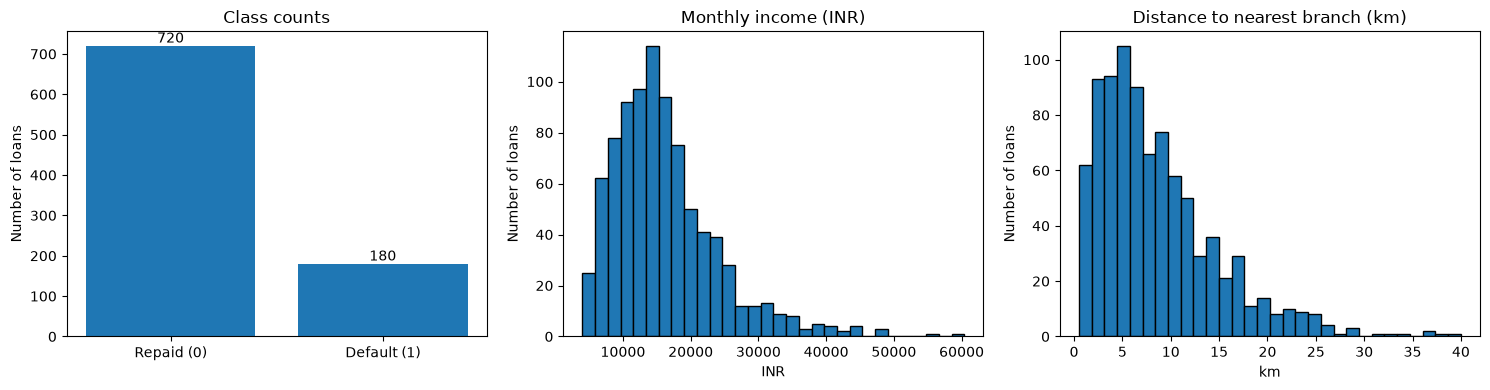

In [23]:
# TASK 1 YOUR CODE HERE
# 1.1 shape, dtypes, class counts and proportions, summary statistics, missing values per column
print('1. shape:',student_data.shape,'\n')
print('2. dtypes:\n',student_data.dtypes,'\n')
print('3. class counts and proportions:\n',student_data['default'].value_counts(normalize=True).round(3),'\n')
print('4. summary statistics:\n',student_data.describe().round(2),'\n')
print('5. missing values per column:\n',student_data.isna().sum(),'\n')

# 1.2 at least two plots
counts = student_data["default"].value_counts().sort_index()

plt.figure(figsize=(15, 4)) # to create a empty figure

# Plot 1: class counts
plt.subplot(1, 3, 1)
bars = plt.bar(counts.index, counts.values)
plt.bar_label(bars)
plt.xticks([0, 1], ["Repaid (0)", "Default (1)"])
plt.title("Class counts")
plt.ylabel("Number of loans")

# Plot 2: monthly income
plt.subplot(1, 3, 2)
plt.hist(student_data["monthly_income"].dropna(), bins=30, edgecolor="black")
plt.title("Monthly income (INR)")
plt.xlabel("INR")
plt.ylabel("Number of loans")

# Plot 3: distance to branch
plt.subplot(1, 3, 3)
plt.hist(student_data["branch_distance_km"].dropna(), bins=30, edgecolor="black")
plt.title("Distance to nearest branch (km)")
plt.xlabel("km")
plt.ylabel("Number of loans")

plt.tight_layout()
plt.show()


**Task 1 written answer (2 marks).** State three observations from your inspection that will matter for modelling (for example about class balance, differences in feature scales, or missing values), and say why each matters.

**Your answer (maximum 150 words):**

_Write your answer here._

## Task 2 Preparation, split and scaling without leakage (6 marks)
Your train/test split (80%/20%, stratified) and a smaller validation split taken **from the training part only** (`X_fit`, `X_val`) were created for you in Task 0. The **test set must not be used to make any modelling choice.**

Write a function `prepare_features(X_fit, X_apply)` that:

2.1 computes the **median of each column from `X_fit` only** and uses it to fill missing values in both `X_fit` and `X_apply` *(2 marks)*;

2.2 fits a `StandardScaler` on the **imputed `X_fit` only** and uses it to scale both *(2 marks)*;

2.3 returns four objects: imputed `X_fit`, imputed `X_apply`, scaled `X_fit`, scaled `X_apply`.

Then call it for (`X_train`, `X_test`) and for (`X_fit`, `X_val`).

In [42]:
# TASK 2 YOUR CODE HERE
def prepare_features(X_fit, X_apply):
    # fill missing values using medians computed on X_fit only
    medians = X_fit.median()
    fit_imp = X_fit.fillna(medians)
    apply_imp = X_apply.fillna(medians)

    # fit the scaler on the imputed X_fit only
    scaler = StandardScaler().set_output(transform='pandas')
    fit_sc = scaler.fit_transform(fit_imp)
    apply_sc = scaler.transform(apply_imp)

    # return fit_imp, apply_imp, fit_sc, apply_sc
    return fit_imp, apply_imp, fit_sc, apply_sc

# final-model data:  Xtr_imp, Xte_imp, Xtr_sc, Xte_sc = prepare_features(X_train, X_test)
Xtr_imp, Xte_imp, Xtr_sc, Xte_sc = prepare_features(X_train, X_test)

# validation data:   Xfit_imp, Xval_imp, Xfit_sc, Xval_sc = prepare_features(X_fit, X_val)
Xfit_imp, Xval_imp, Xfit_sc, Xval_sc = prepare_features(X_fit, X_val)

# checks: no missing values remain; scaled training columns have mean about 0 and std about 1
print('Missing after imputation:','\n',
        'Train:',Xtr_imp.isna().sum().sum(),
        'Test:',Xte_imp.isna().sum().sum(),
        'Fit:',Xfit_imp.isna().sum().sum(),
        'Val:',Xval_imp.isna().sum().sum(), '\n')

print('Scaled training columns, mean (about 0):','\n', 
        Xtr_sc.mean().round(3), '\n')
print('Scaled training columns, std (about 1):','\n',
        Xtr_sc.std(ddof=0).round(3))

Missing after imputation: 
 Train: 0 Test: 0 Fit: 0 Val: 0 

Scaled training columns, mean (about 0): 
 age                   0.0
monthly_income        0.0
loan_amount           0.0
term_months           0.0
prior_loans          -0.0
agri_income_share     0.0
branch_distance_km   -0.0
savings_group         0.0
dtype: float64 

Scaled training columns, std (about 1): 
 age                   1.0
monthly_income        1.0
loan_amount           1.0
term_months           1.0
prior_loans           1.0
agri_income_share     1.0
branch_distance_km    1.0
savings_group         1.0
dtype: float64


**Task 2 written answer (2 marks).** Explain what *data leakage* would occur if you computed the medians or the scaling parameters on the full dataset (train + test), and why that makes test results less trustworthy.

**Your answer (maximum 120 words):**

_Write your answer here._

## Task 3 Baseline (3 marks)
Create a **majority-class baseline** with `DummyClassifier(strategy="most_frequent")`, fitted on the training data. Report its confusion matrix on the test set, its accuracy and its recall for the positive class *(1 mark)*.

refer to DummyClassifier in scikit learn documentation. 

In [ ]:
# TASK 3 YOUR CODE HERE
DummyClassifier(strategy="most_frequent")


**Task 3 written answer (2 marks).** Why is a baseline useful? What do the baseline's accuracy and recall tell you about judging models on this dataset?

**Your answer (maximum 100 words):**

_Write your answer here._

## Task 4 Model building (8 marks)
Use the **assigned** `K_ASSIGNED` and `DEPTH_ASSIGNED`. Fit on the **training data** only.

| Model | Settings | Input to use |
|---|---|---|
| Logistic regression | `max_iter=1000` | scaled |
| KNN | `n_neighbors=K_ASSIGNED` | scaled |
| Gaussian Naive Bayes | defaults | imputed (unscaled) |
| Decision tree | `criterion="entropy"`, `max_depth=DEPTH_ASSIGNED`, `random_state=SEED` | imputed (unscaled) |
| Linear SVM | `SVC(kernel="linear", C=1.0)` | scaled |

**4.1** Fit the five models *(4 marks)*. 

**4.2** *(2 marks)* Using the **validation split** (not the test set), compare KNN with `K_ASSIGNED` on **scaled** versus **unscaled** inputs (accuracy and recall on `X_val`) and explain in words what you see. 

**4.3** *(2 marks)* Print the rules of your decision tree with `export_text`, and explain the **root split** using the idea of **information gain**.

In [ ]:
# TASK 4 YOUR CODE HERE

# 4.1 fit the five models


# 4.2 KNN on validation data: scaled vs unscaled inputs


# 4.3 print the tree rules


**Task 4 written answers.**

**4.2** What do you observe, and why does feature scaling matter for KNN? *(maximum 100 words)*

_Write your answer here._

**4.3** Which feature does the tree split on first? Explain, in terms of information gain (reduction in entropy), why a split like this is chosen. *(maximum 100 words)*

_Write your answer here._

## Task 5 Parameter reasoning (6 marks)
All comparisons in this task use the **training/validation split only** (`Xfit_*`, `Xval_*`), never the test set. Use **F1-score for the positive class** as the measure.

**5.1 K in KNN** *(2 marks)*: for K in `[1, 3, 5, 7, 9, 11, 15, 21, 31]`, fit KNN on the scaled fit data, compute F1 on the fit data and on the validation data, and plot both against K.

**5.2 Depth of the tree** *(2 marks)*: for `max_depth` from 1 to 10 (`criterion="entropy"`), do the same on the imputed data.

**5.3 Regularization C in a linear SVM** *(2 marks)*: for C in `[0.01, 1, 100]`, fit `SVC(kernel="linear", C=C)` on the **scaled training data** (`Xtr_sc`) and report the total number of support vectors (`model.n_support_.sum()`).

In [ ]:
# TASK 5 YOUR CODE HERE
K_GRID = [1, 3, 5, 7, 9, 11, 15, 21, 31]
DEPTH_GRID = list(range(1, 11))
C_GRID = [0.01, 1, 100]

# 5.1 KNN sweep + plot


# 5.2 tree depth sweep + plot


# 5.3 SVM support vectors for each C


**Task 5 written answers.**

**5.1** Describe how fit F1 and validation F1 change as K increases, and what this says about small and large K. *(maximum 120 words)*

_Write your answer here._

**5.2** Describe how fit and validation F1 change with depth, and where overfitting begins to appear. Comment on whether your assigned depth looks reasonable. *(maximum 120 words)*

_Write your answer here._

**5.3** How does the number of support vectors change with C, and what does this say about the margin and about regularization? *(maximum 100 words)*

_Write your answer here._

## Task 6 Evaluation (8 marks)

**6.1** *(2 marks)* For the baseline and all five models, compute the confusion matrix on the **test set** using each model's default decision rule.

**6.2** *(2 marks)* Write your own function `metrics_from_cm(tn, fp, fn, tp)` that returns accuracy, precision, recall, specificity and F1 **from the four counts** (using formulas, not sklearn's metric functions). If a denominator is zero, return `0.0` for that metric. Check your function against sklearn for at least one model.

**6.3** *(2 marks)* Compute **ROC-AUC from scores, not from class labels**: `predict_proba(...)[:, 1]` for LR, KNN, Naive Bayes and the tree, and `decision_function(...)` for the linear SVM. Plot the ROC curves of the five models on one figure.

**6.4** *(2 marks)* Present one table with all six rows (baseline + five models) and the six metrics (accuracy, precision, recall, specificity, F1, ROC-AUC).

In [ ]:
# TASK 6 YOUR CODE HERE
def metrics_from_cm(tn, fp, fn, tp):
    # return a dict with accuracy, precision, recall, specificity, f1
    ...


# loop over the baseline and the five models: confusion matrix, metrics, ROC-AUC from scores


# ROC plot


# results table (DataFrame called `results`)


## Task 7 Interpretation and reflection (6 marks)
**7.1** *(2 marks, maximum 200 words)* The lender says: "A missed defaulter (false negative) costs us far more than wrongly refusing a good borrower (false positive)." Using your results table, which model(s) would you prefer, and why? Is the model with the highest accuracy necessarily the best choice? More than one answer can be defensible; justify yours with numbers from your table.

**7.2** *(2 marks, Python + maximum 120 words)* For **logistic regression**, compare the default threshold 0.5 with a threshold of 0.3 on the test set: report the confusion matrix, precision and recall at each. This is a *descriptive* illustration. Explain what changes and why, and explain why it would be a problem to pick a threshold by looking at test-set performance.

In [ ]:
# TASK 7.2 — YOUR CODE HERE


**7.1 Your answer (maximum 200 words):**

_Write your answer here._

**7.2 Your answer (maximum 120 words):**

_Write your answer here._

**7.3** *(2 marks, maximum 200 words)* List **two** limitations of this dataset or of your evaluation that could make the results misleading, and name the additional evidence you would need before using such a model to make real lending decisions.

**Your answer (maximum 200 words):**

_Write your answer here._

## Final submission checklist and declaration
Tick each item by editing this cell (change `[ ]` to `[x]`):

- [ ] I ran *Restart and run all* and the notebook runs from top to bottom without errors.
- [ ] My **Version ID** is printed in Task 0 and I have written it on the first page of my written paper (Section I and II of the assignment).
- [ ] I am submitting `assignment_config.json`, this notebook (`.ipynb` with outputs), and a PDF export of the notebook.
- [ ] All written answers are within the word limits and in my own words.
- [ ] I can explain every line of my code if asked.

**AI-use declaration** (write "None" if no AI tool was used). Name the tool(s), what you used them for, and which parts of the assignment they touched:

_Write your declaration here._
